# Modeling Human Activity States with a Hidden Markov Model

**Formative 2 – Hidden Markov Models** · Four activities (standing, still, walking, jumping) recorded with a smartphone (Sensor Logger), decoded by a Gaussian-emission HMM implemented **from scratch in NumPy** (forward/backward, Baum–Welch, Viterbi).

**Pipeline**

1. Inventory the raw recordings and measure the real sampling rate of every file
2. Harmonise to a common 100 Hz grid, trim start/stop transients, write cleaned CSVs (`data/processed/`)
3. Slide a 1 s window (50 % overlap) over each recording and extract time- and frequency-domain features
4. Split by *recording* into train / unseen test sessions (no window from a test recording is ever seen in training)
5. Normalise (log + Z-score, statistics from training data only)
6. Build and train the HMM (supervised initialisation → Baum–Welch with a log-likelihood convergence check)
7. Evaluate on the unseen test files, visualise, reflect

Run top-to-bottom from the `notebooks/` folder. Everything is seeded, so the numbers are reproducible.

In [1]:
import glob, json, os, time, warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment

warnings.filterwarnings("ignore")

# ---------- configuration ----------
SEED   = 42
FS     = 100            # common sampling rate after harmonisation (Hz)
WIN    = 100            # window length in samples  -> 1.0 s at 100 Hz
HOP    = 50             # hop in samples            -> 50 % overlap
TRIM_S = 0.5            # seconds trimmed at both ends of every recording
ACTS   = ["standing", "standstill", "walking", "jumping"]   # hidden states Z (index = state id)
COLORS = {"standing": "#3b6fb6", "standstill": "#8a8f98", "walking": "#3f9b6a", "jumping": "#e08a2c"}

RAW_DIR, PROC_DIR, TEST_DIR, FIG_DIR = "../data/raw", "../data/processed", "../data/test", "../figures"
for d in (PROC_DIR, TEST_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 9})
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.4.4 | pandas 3.0.2


## 1. Data inventory and real sampling rates

Sensor Logger exports one folder per recording with `Accelerometer.csv`, `Gyroscope.csv`, `TotalAcceleration.csv` and `Metadata.csv`. The metadata *requests* a 10 ms interval, but phones never deliver perfectly regular samples, so the **measured** rate is computed from the timestamps of every file.

In [2]:
def read_sensor(folder, sensor):
    df = pd.read_csv(os.path.join(folder, f"{sensor}.csv"))
    df = df[df["seconds_elapsed"] >= 0].drop_duplicates("seconds_elapsed")   # drop pre-start samples
    return df.reset_index(drop=True)

rows = []
for act in ACTS:
    for folder in sorted(glob.glob(f"{RAW_DIR}/{act}/*/")):
        meta = pd.read_csv(folder + "Metadata.csv").iloc[0]
        acc, gyr = read_sensor(folder, "Accelerometer"), read_sensor(folder, "Gyroscope")
        t = acc["seconds_elapsed"].values
        rows.append(dict(activity=act, recording=os.path.basename(folder.rstrip("/")),
                         device=meta["device name"], platform=meta["platform"], app_version=meta["appVersion"],
                         requested_ms=str(meta["sampleRateMs"]).split("|")[0],
                         duration_s=t[-1] - t[0], acc_hz=(len(acc) - 1) / (t[-1] - t[0]),
                         gyr_hz=(len(gyr) - 1) / (gyr["seconds_elapsed"].iloc[-1] - gyr["seconds_elapsed"].iloc[0]),
                         max_gap_ms=1000 * np.diff(t).max()))
inv = pd.DataFrame(rows)
inv.to_csv("../data/inventory.csv", index=False)

print("Devices:", inv.groupby(["device", "platform", "app_version", "requested_ms"]).size().to_dict())
print(f"\nTotal recordings: {len(inv)}\n")
summary = inv.groupby("activity").agg(files=("recording", "count"), total_s=("duration_s", "sum"),
                                      min_dur=("duration_s", "min"), mean_dur=("duration_s", "mean"),
                                      max_dur=("duration_s", "max"), acc_hz=("acc_hz", "mean"),
                                      gyr_hz=("gyr_hz", "mean"), worst_gap_ms=("max_gap_ms", "max")).loc[ACTS]
print(summary.round(2).to_string())
print(f"\nMeasured accelerometer rate over all files: {inv.acc_hz.mean():.2f} Hz (min {inv.acc_hz.min():.2f}, max {inv.acc_hz.max():.2f})")
print(f"Files shorter than 5 s: {(inv.duration_s < 5).sum()}  |  longer than 10 s: {(inv.duration_s > 10).sum()}")

Devices: {('SM-G973F', 'android', 1.68, '10'): 200}

Total recordings: 200

            files  total_s  min_dur  mean_dur  max_dur  acc_hz  gyr_hz  worst_gap_ms
activity                                                                            
standing       50   286.94     4.69      5.74     9.24   99.71   99.91         99.77
standstill     50   315.70     4.74      6.31     8.08   99.90   99.92         68.49
walking        50   287.31     4.19      5.75     7.43   99.81   99.91         86.55
jumping        50   303.50     4.05      6.07     8.86   99.92   99.92         50.99

Measured accelerometer rate over all files: 99.84 Hz (min 98.17, max 100.10)
Files shorter than 5 s: 17  |  longer than 10 s: 0


## 2. Harmonisation, trimming and cleaning

* **Common grid.** Accelerometer and gyroscope are logged as *separate* streams with slightly different timestamps (and occasional gaps of >10 ms), so they cannot simply be stacked row by row. Every stream is linearly interpolated onto one **100 Hz grid**. 100 Hz is the measured rate of this phone, so almost no information is invented; any other member's phone is brought to the same 100 Hz grid with the same function.
* **Trimming.** The first and last 0.5 s of each recording contain the finger tapping *start/stop* on the screen. Several gyroscope files also start with a single spike sample. Trimming both ends removes both effects.
* **Timestamp column.** Each cleaned file keeps an epoch timestamp (`timestamp_ns`) and a relative `time_s`.

In [3]:
def harmonise(folder, fs=FS, trim=TRIM_S):
    # Merge accelerometer, gyroscope, total-acceleration of ONE recording onto a regular grid.
    streams = {"acc": read_sensor(folder, "Accelerometer"), "gyro": read_sensor(folder, "Gyroscope"),
               "tot": read_sensor(folder, "TotalAcceleration")}
    t0 = max(s["seconds_elapsed"].iloc[0]  for s in streams.values()) + trim
    t1 = min(s["seconds_elapsed"].iloc[-1] for s in streams.values()) - trim
    grid = np.arange(t0, t1, 1.0 / fs)
    out = {"time_s": grid - grid[0]}
    ref = streams["acc"]                                                  # epoch reference
    out["timestamp_ns"] = (ref["time"].iloc[0] + (grid - ref["seconds_elapsed"].iloc[0]) * 1e9).astype("int64")
    for name, df in streams.items():
        for ax in "xyz":
            out[f"{name}_{ax}"] = np.interp(grid, df["seconds_elapsed"], df[ax])
    return pd.DataFrame(out)

processed = {}                     # recording id -> DataFrame
for act in ACTS:
    for folder in sorted(glob.glob(f"{RAW_DIR}/{act}/*/")):
        rec = os.path.basename(folder.rstrip("/"))
        df = harmonise(folder)
        df["activity"], df["recording"] = act, rec
        df.to_csv(f"{PROC_DIR}/{rec}.csv", index=False)
        processed[rec] = df

lens = pd.Series({r: len(d) / FS for r, d in processed.items()})
by_act = pd.Series({a: sum(len(d) for r, d in processed.items() if d.activity.iloc[0] == a) / FS for a in ACTS})
print(f"{len(processed)} cleaned files written to {PROC_DIR}")
print("Seconds of clean signal per activity:\n", by_act.round(1).to_string())
print(f"Clean file length: min {lens.min():.2f}s  mean {lens.mean():.2f}s  max {lens.max():.2f}s")

200 cleaned files written to ../data/processed
Seconds of clean signal per activity:
 standing      233.0
standstill    261.2
walking       233.8
jumping       248.5
Clean file length: min 2.95s  mean 4.88s  max 8.13s


Raw sample spacing: median 10.00 ms | 99th pct 10.0 ms | max 100 ms | 0.04% of gaps > 15 ms


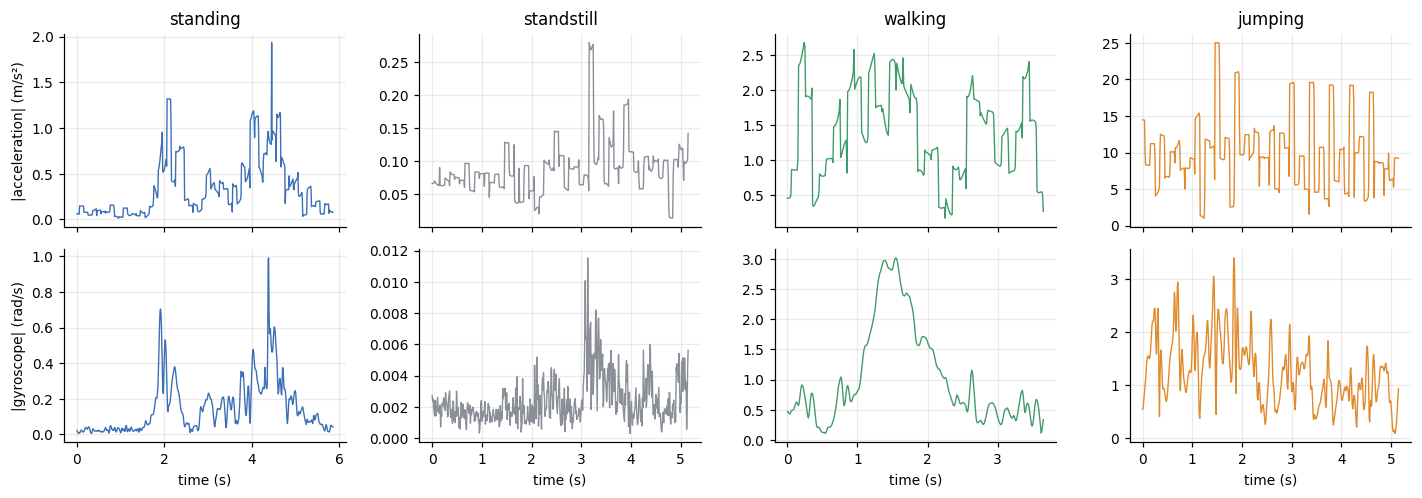

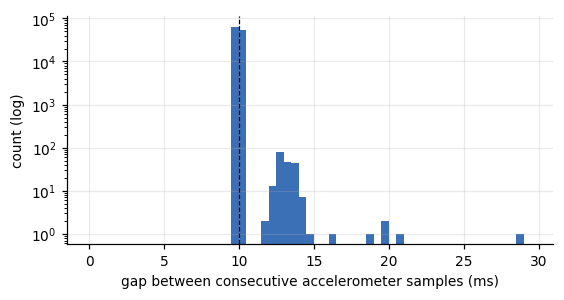

In [4]:
# Figure 1 - what the signals look like; Figure 2 - how irregular the raw timestamps are
fig, axes = plt.subplots(2, 4, figsize=(13, 4.6), sharex="col")
for j, act in enumerate(ACTS):
    d = processed[f"{act}_05"]
    am = np.linalg.norm(d[["acc_x", "acc_y", "acc_z"]].values, axis=1)
    gm = np.linalg.norm(d[["gyro_x", "gyro_y", "gyro_z"]].values, axis=1)
    axes[0, j].plot(d.time_s, am, color=COLORS[act], lw=.9); axes[0, j].set_title(act)
    axes[1, j].plot(d.time_s, gm, color=COLORS[act], lw=.9); axes[1, j].set_xlabel("time (s)")
axes[0, 0].set_ylabel("|acceleration| (m/s²)"); axes[1, 0].set_ylabel("|gyroscope| (rad/s)")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/fig1_sample_signals.png", dpi=170, bbox_inches="tight")

gaps = np.concatenate([np.diff(read_sensor(f, "Accelerometer")["seconds_elapsed"].values) * 1000
                       for f in sorted(glob.glob(f"{RAW_DIR}/*/*/"))])
fig, ax = plt.subplots(figsize=(5.2, 2.8))
ax.hist(gaps, bins=np.arange(0, 30, .5), color="#3b6fb6"); ax.set_yscale("log")
ax.set_xlabel("gap between consecutive accelerometer samples (ms)"); ax.set_ylabel("count (log)")
ax.axvline(10, color="k", ls="--", lw=.8)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/fig2_timestamp_gaps.png", dpi=170, bbox_inches="tight")
print(f"Raw sample spacing: median {np.median(gaps):.2f} ms | 99th pct {np.percentile(gaps, 99):.1f} ms | max {gaps.max():.0f} ms "
      f"| {np.mean(gaps > 15) * 100:.2f}% of gaps > 15 ms")

## 3. Windowing and feature extraction

**Window = 1.0 s (100 samples at 100 Hz), hop = 0.5 s (50 % overlap).** The window is chosen from the sampling rate and the physics of the activities:

* walking cadence is about 1.5–2.5 steps/s and jumping about 2–4 jumps/s, so 1 s always contains at least two full movement cycles;
* a 1 s window gives an FFT resolution of 1 Hz, and the Nyquist limit at 100 Hz (50 Hz) is far above any body-motion frequency;
* longer windows would leave only ~4–5 windows in the shortest recordings and blur activity boundaries; 50 % overlap doubles the number of observations without hiding transitions.

Features are computed on the acceleration **magnitude** and gyroscope **magnitude** (orientation-independent, so a phone held slightly differently still looks the same) plus per-axis quantities.

| Feature | Domain | Why it helps |
|---|---|---|
| `acc_mean`, `acc_std`, `acc_rms` | time | overall vigour of motion: jumping ≫ walking ≫ standing > still |
| `acc_sma` (signal magnitude area) | time | classic activity-intensity measure, sums all three axes |
| `gyr_std`, `gyr_rms`, `gyr_sma` | time | rotation of the phone: walking sways, jumping tumbles, a phone lying flat has ~0 |
| `acc_corr` | time | mean pairwise correlation between x, y, z: vertical bouncing couples axes, walking less so |
| `dom_freq` | frequency (FFT) | step / jump rhythm: ≈2 Hz walking vs ≈4 Hz jumping |
| `spec_energy` | frequency (FFT) | total power of the non-DC spectrum: separates energetic from quiet states |
| `spec_entropy` | frequency (FFT) | periodic motion (walking) concentrates power in few bins; noise-like postural sway spreads it |

In [5]:
FEATURES = ["acc_mean", "acc_std", "acc_rms", "acc_sma", "gyr_std", "gyr_rms", "gyr_sma",
            "acc_corr", "dom_freq", "spec_energy", "spec_entropy"]
LOG_FEATURES = ["acc_mean", "acc_std", "acc_rms", "acc_sma", "gyr_std", "gyr_rms", "gyr_sma", "spec_energy"]
SIGNAL_COLS = ["acc_x", "acc_y", "acc_z", "gyro_x", "gyro_y", "gyro_z", "tot_x", "tot_y", "tot_z"]

def window_features(w):
    # w: (WIN, 9) array -> dict of features. Columns: acc xyz, gyro xyz, total-acc xyz.
    a, g, t = w[:, 0:3], w[:, 3:6], w[:, 6:9]
    am, gm = np.linalg.norm(a, axis=1), np.linalg.norm(g, axis=1)
    f = {"acc_mean": am.mean(), "acc_std": am.std(), "acc_rms": np.sqrt((am ** 2).mean()),
         "acc_sma": np.abs(a).sum(axis=1).mean(),
         "gyr_std": gm.std(), "gyr_rms": np.sqrt((gm ** 2).mean()), "gyr_sma": np.abs(g).sum(axis=1).mean()}
    c = np.corrcoef(a.T)
    f["acc_corr"] = np.nanmean([c[0, 1], c[0, 2], c[1, 2]])
    x = am - am.mean()                                                  # remove DC before the FFT
    P = np.abs(np.fft.rfft(x * np.hanning(len(x)))) ** 2                # Hann window limits leakage
    freqs = np.fft.rfftfreq(len(x), 1.0 / FS)
    f["dom_freq"] = freqs[1:][P[1:].argmax()]
    f["spec_energy"] = P[1:].sum() / len(x)
    p = P[1:] / (P[1:].sum() + 1e-12)
    f["spec_entropy"] = -(p * np.log(p + 1e-12)).sum()
    gv = t.mean(axis=0)                                                 # gravity direction (extra, used only in ablation)
    f["tilt_deg"] = np.degrees(np.arccos(gv[2] / np.linalg.norm(gv)))
    return f

def featurise(df):
    # Window ONE recording (never across a recording boundary) -> DataFrame of features.
    W, out = df[SIGNAL_COLS].values, []
    for s in range(0, len(W) - WIN + 1, HOP):
        r = window_features(W[s:s + WIN]); r["win_start_s"] = s / FS; out.append(r)
    r = pd.DataFrame(out); r["activity"], r["recording"] = df["activity"].iloc[0], df["recording"].iloc[0]
    return r

feat = pd.concat([featurise(d) for d in processed.values()], ignore_index=True)
feat.to_csv("../data/features_all_windows.csv", index=False)
print("windows per activity:", feat.groupby("activity").size().loc[ACTS].to_dict())
print(feat.groupby("activity")[FEATURES].mean().loc[ACTS].T.round(3).to_string())

windows per activity: {'standing': 388, 'standstill': 450, 'walking': 395, 'jumping': 422}
activity      standing  standstill  walking  jumping
acc_mean         0.180       0.071    1.447   10.676
acc_std          0.093       0.014    0.557    5.657
acc_rms          0.204       0.073    1.558   12.143
acc_sma          0.263       0.091    2.166   15.652
gyr_std          0.034       0.001    0.397    0.673
gyr_rms          0.068       0.002    0.983    1.501
gyr_sma          0.085       0.002    1.294    2.016
acc_corr         0.143       0.048    0.059    0.012
dom_freq         2.528       2.600    1.878    3.986
spec_energy      0.254       0.012    5.797  663.774
spec_entropy     2.196       2.390    1.913    2.319


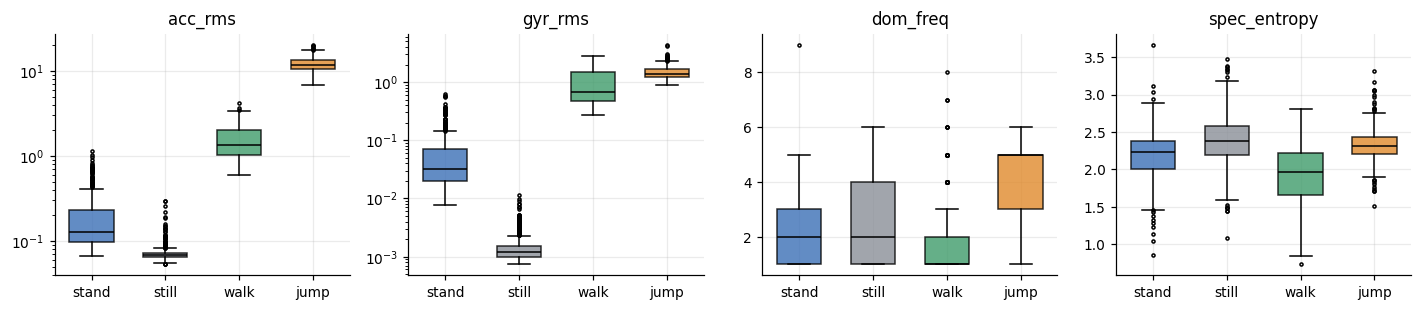

In [6]:
# Figure 3 - do the features separate the activities?
show = [("acc_rms", "log"), ("gyr_rms", "log"), ("dom_freq", "lin"), ("spec_entropy", "lin")]
fig, axes = plt.subplots(1, 4, figsize=(13, 2.9))
for ax, (f, sc) in zip(axes, show):
    data = [feat[feat.activity == a][f].values for a in ACTS]
    bp = ax.boxplot(data, labels=["stand", "still", "walk", "jump"], patch_artist=True, widths=.6,
                    medianprops=dict(color="k"), flierprops=dict(markersize=2))
    for patch, a in zip(bp["boxes"], ACTS): patch.set_facecolor(COLORS[a]); patch.set_alpha(.8)
    ax.set_title(f); ax.set_yscale("log" if sc == "log" else "linear")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/fig3_feature_distributions.png", dpi=170, bbox_inches="tight")

## 4. Unseen test data

The raw data contains 50 recordings per activity, all from the same phone, so *unseen* data is created by **holding out whole recordings** (never windows): 10 recordings per activity (20 %) are set aside with a fixed seed and stitched into **two test files** (`data/test/test_session_1.csv`, `test_session_2.csv`), each containing 5 recordings of every activity in random order. The remaining 40 recordings per activity are used for training. Because the held-out recordings come from the same phone, person and sessions as the training recordings, this measures generalisation to *new recordings*, not to new people or devices (discussed in the report).

In [7]:
rng = np.random.default_rng(SEED)
recs_by_act = {a: sorted(r for r, d in processed.items() if d.activity.iloc[0] == a) for a in ACTS}
test_recs  = {a: sorted(str(r) for r in rng.choice(recs_by_act[a], 10, replace=False)) for a in ACTS}
train_recs = {a: [r for r in recs_by_act[a] if r not in test_recs[a]] for a in ACTS}

test_sessions = []
for i in range(2):
    ids = [r for a in ACTS for r in test_recs[a][i * 5:(i + 1) * 5]]
    rng.shuffle(ids)
    df = pd.concat([processed[r] for r in ids], ignore_index=True)
    df.insert(0, "session_time_s", np.arange(len(df)) / FS)           # continuous clock across stitched recordings
    df.to_csv(f"{TEST_DIR}/test_session_{i + 1}.csv", index=False)
    test_sessions.append(list(ids))
    print(f"test_session_{i + 1}.csv  {len(df) / FS:6.1f} s  recordings: {ids}")
print("\ntraining recordings per activity:", {a: len(v) for a, v in train_recs.items()})

test_session_1.csv    98.2 s  recordings: ['walking_17', 'standing_20', 'jumping_30', 'standing_10', 'standstill_20', 'jumping_07', 'standing_04', 'standstill_16', 'walking_12', 'walking_08', 'jumping_16', 'walking_22', 'standstill_09', 'jumping_20', 'standing_29', 'standing_05', 'walking_04', 'jumping_17', 'standstill_19', 'standstill_22']
test_session_2.csv    94.9 s  recordings: ['jumping_32', 'jumping_34', 'standing_40', 'walking_27', 'standstill_41', 'standing_33', 'standstill_31', 'jumping_46', 'standing_50', 'standstill_42', 'walking_34', 'standstill_28', 'walking_47', 'jumping_50', 'walking_45', 'walking_32', 'standing_34', 'jumping_41', 'standing_45', 'standstill_36']

training recordings per activity: {'standing': 40, 'standstill': 40, 'walking': 40, 'jumping': 40}


## 5. Normalisation

1. **log10 transform** of the eight intensity features (`*_mean/std/rms/sma`, `spec_energy`). They span 3–5 orders of magnitude (a phone lying still vs. jumping) and are strongly right-skewed; a Gaussian emission model fits their logarithm far better than the raw values.
2. **Z-score** (zero mean, unit variance) per feature, with mean and standard deviation estimated **on training windows only** and re-used unchanged for test data. Z-scoring puts all 11 features on the same scale so no feature dominates the likelihood, and it is the standard choice when the model assumes Gaussian emissions. Fitting the scaler on training data only prevents leakage of test statistics.

In [8]:
class Scaler:
    # log10 on skewed features, then Z-score with statistics fitted on training windows only.
    def __init__(self, cols): self.cols = cols
    def _log(self, df):
        X = df[self.cols].copy()
        for c in self.cols:
            if c in LOG_FEATURES: X[c] = np.log10(X[c] + 1e-4)
        return X
    def fit(self, df):
        X = self._log(df); self.mu, self.sd = X.mean(), X.std() + 1e-9; return self
    def transform(self, df): return ((self._log(df) - self.mu) / self.sd).values

def session_xy(feat_df, rec_ids, scaler):
    # Stitch recordings (in the given order) into ONE observation sequence X and its true state sequence z.
    Xs, zs = [], []
    for r in rec_ids:
        g = feat_df[feat_df.recording == r].sort_values("win_start_s")
        Xs.append(scaler.transform(g)); zs.append(np.full(len(g), ACTS.index(g.activity.iloc[0])))
    return np.vstack(Xs), np.concatenate(zs)

def make_sessions(rec_by_act, n_sessions, rng):
    # Partition recordings (each used exactly once) into n_sessions shuffled sessions with equal counts per activity.
    parts = {a: np.array_split(rng.permutation(rec_by_act[a]), n_sessions) for a in ACTS}
    sessions = []
    for s in range(n_sessions):
        ids = [str(r) for a in ACTS for r in parts[a][s]]; rng.shuffle(ids); sessions.append(ids)
    return sessions

## 6. HMM definition

| Element | Definition in this project |
|---|---|
| **Hidden states Z** | 4 activities: `standing`, `standstill` (still), `walking`, `jumping` |
| **Observations X** | one 11-dimensional normalised feature vector per 1 s window |
| **Transition matrix A** | `A[i, j] = P(Z_{t+1} = j | Z_t = i)` (4×4, rows sum to 1) |
| **Emission B** | `P(X_t | Z_t = k) = N(μ_k, diag σ²_k)` – a diagonal Gaussian per state |
| **Initial distribution π** | probability that a session starts in each state |

**Which algorithms, and how they tie to the evaluation metrics (brief).**
* **Viterbi** returns the single most probable *state sequence* given all observations, so it directly produces the per-window activity labels from which **sensitivity, specificity, accuracy and the confusion matrix** are computed. It is used for decoding.
* **Baum–Welch (EM)** with the **forward–backward** algorithm learns *A, π, μ, σ²* from data by maximising the observation log-likelihood; the **log-likelihood curve** is its convergence diagnostic. It is initialised from labelled windows (supervised initialisation) so each hidden state is anchored to a known activity.
* Maximising likelihood is not the same as maximising accuracy, so Baum–Welch is compared against the label-only fit in cross-validation (section 8).

In [9]:
def logsumexp(a, axis=None):
    m = np.max(a, axis=axis, keepdims=True); m = np.where(np.isfinite(m), m, 0.0)
    out = m + np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True))
    return out.squeeze() if axis is None else np.squeeze(out, axis=axis)

class GaussianHMM:
    # Hidden Markov model with diagonal-Gaussian emissions; all inference in log space (numerically stable).
    def __init__(self, n_states, var_floor=1e-2):
        self.K, self.var_floor = n_states, var_floor

    # ---- parameter initialisation ----
    def init_supervised(self, seqs, labels):
        X, z = np.vstack(seqs), np.concatenate(labels)
        self.mu  = np.array([X[z == k].mean(0) for k in range(self.K)])
        self.var = np.array([X[z == k].var(0) + self.var_floor for k in range(self.K)])
        A = np.ones((self.K, self.K))                                  # Laplace smoothing
        for l in labels:
            for a, b in zip(l[:-1], l[1:]): A[a, b] += 1
        self.A = A / A.sum(1, keepdims=True)
        pi = np.ones(self.K)
        for l in labels: pi[l[0]] += 1
        self.pi = pi / pi.sum(); self._sync(); return self

    def init_random(self, seqs, rng):
        X = np.vstack(seqs)
        self.mu  = X[rng.choice(len(X), self.K, replace=False)].copy()
        self.var = np.tile(X.var(0) + self.var_floor, (self.K, 1))
        A = rng.random((self.K, self.K)) + 2 * np.eye(self.K); self.A = A / A.sum(1, keepdims=True)
        self.pi = np.ones(self.K) / self.K; self._sync(); return self

    def _sync(self): self.logA, self.logpi = np.log(self.A + 1e-300), np.log(self.pi + 1e-300)

    # ---- inference ----
    def log_emission(self, X):                       # (T, K): log N(x_t | mu_k, diag var_k)
        d = X.shape[1]; diff = X[:, None, :] - self.mu[None]
        return -0.5 * (d * np.log(2 * np.pi) + np.log(self.var).sum(1)[None] + (diff ** 2 / self.var[None]).sum(2))

    def forward(self, logB):
        la = np.zeros_like(logB); la[0] = self.logpi + logB[0]
        for t in range(1, len(logB)):
            la[t] = logsumexp(la[t - 1][:, None] + self.logA, axis=0) + logB[t]
        return la

    def backward(self, logB):
        lb = np.zeros_like(logB)
        for t in range(len(logB) - 2, -1, -1):
            lb[t] = logsumexp(self.logA + (logB[t + 1] + lb[t + 1])[None], axis=1)
        return lb

    def score(self, X): return float(logsumexp(self.forward(self.log_emission(X))[-1]))
    def total_ll(self, seqs): return sum(self.score(X) for X in seqs)

    def viterbi(self, X):
        T, logB = len(X), self.log_emission(X)
        delta, psi = np.zeros((T, self.K)), np.zeros((T, self.K), int)
        delta[0] = self.logpi + logB[0]
        for t in range(1, T):
            s = delta[t - 1][:, None] + self.logA
            psi[t], delta[t] = s.argmax(0), s.max(0) + logB[t]
        path = np.zeros(T, int); path[-1] = delta[-1].argmax()
        for t in range(T - 2, -1, -1): path[t] = psi[t + 1, path[t + 1]]
        return path, float(delta[-1].max())

    def predict_independent(self, X):                # ignore A: per-window maximum a-posteriori under emissions + pi
        return (self.log_emission(X) + self.logpi).argmax(1)

    # ---- learning ----
    def fit(self, seqs, tol=1e-2, max_iter=200):
        # Baum-Welch (EM). Stops when the improvement in total log-likelihood falls below tol (epsilon).
        hist, prev = [], -np.inf
        for it in range(max_iter):
            g_sum, xi_sum = np.zeros(self.K), np.zeros((self.K, self.K))
            s1, s2 = np.zeros_like(self.mu), np.zeros_like(self.mu)
            pi_new, ll = np.zeros(self.K), 0.0
            for X in seqs:
                logB = self.log_emission(X); la, lb = self.forward(logB), self.backward(logB)
                l = logsumexp(la[-1]); ll += l
                gamma = np.exp(la + lb - l)                                    # P(Z_t = k | X)
                pi_new += gamma[0]
                for t in range(len(X) - 1):                                    # P(Z_t = i, Z_t+1 = j | X)
                    xi_sum += np.exp(la[t][:, None] + self.logA + (logB[t + 1] + lb[t + 1])[None] - l)
                g_sum += gamma.sum(0); s1 += gamma.T @ X; s2 += gamma.T @ (X ** 2)
            self.pi = pi_new / pi_new.sum()
            self.A  = (xi_sum + 1e-6) / (xi_sum + 1e-6).sum(1, keepdims=True)
            self.mu = s1 / g_sum[:, None]
            self.var = np.maximum(s2 / g_sum[:, None] - self.mu ** 2, 0) + self.var_floor
            self._sync(); hist.append(ll)                                      # ll is that of the parameters BEFORE this update
            if abs(ll - prev) < tol: break
            prev = ll
        hist.append(self.total_ll(seqs))                                       # final value after last update
        return hist

### Correctness checks

Before trusting the implementation: (1) compare the forward algorithm and Viterbi against **brute-force enumeration** of every state path on a tiny random model, and (2) confirm that Baum–Welch never decreases the training log-likelihood (the EM guarantee).

In [10]:
import itertools
rt = np.random.default_rng(0)
K, T, d = 3, 6, 2
m = GaussianHMM(K, var_floor=1e-2)
m.mu, m.var = rt.normal(size=(K, d)), rt.uniform(.5, 1.5, size=(K, d))
A = rt.random((K, K)); m.A = A / A.sum(1, keepdims=True); p = rt.random(K); m.pi = p / p.sum(); m._sync()
X = rt.normal(size=(T, d)); logB = m.log_emission(X)

path_lp = {}
for path in itertools.product(range(K), repeat=T):
    lp = m.logpi[path[0]] + logB[0, path[0]]
    for t in range(1, T): lp += m.logA[path[t - 1], path[t]] + logB[t, path[t]]
    path_lp[path] = lp
brute_ll   = logsumexp(np.array(list(path_lp.values())))
brute_best = max(path_lp, key=path_lp.get)
vpath, vlp = m.viterbi(X)
print(f"forward  log-likelihood: {m.score(X):.10f}   brute force: {brute_ll:.10f}   -> match: {np.isclose(m.score(X), brute_ll)}")
print(f"Viterbi path == brute-force best path: {tuple(vpath) == brute_best}   (log-prob {vlp:.6f} vs {path_lp[brute_best]:.6f})")

# posterior sanity: gamma rows sum to 1 and forward/backward agree on the likelihood at every t
la, lb = m.forward(logB), m.backward(logB)
print("forward/backward agree at every t:", np.allclose([logsumexp(la[t] + lb[t]) for t in range(T)], brute_ll))

forward  log-likelihood: -14.2097857479   brute force: -14.2097857479   -> match: True
Viterbi path == brute-force best path: True   (log-prob -17.980054 vs -17.980054)
forward/backward agree at every t: True


## 7. Training: three variants

| Variant | What it does |
|---|---|
| **Supervised (label-only)** | μ, σ², A, π from the labelled training windows (maximum-likelihood counts) – no EM |
| **Supervised init + Baum–Welch** *(primary model)* | start from the supervised parameters, then refine with EM until the log-likelihood gain is < ε = 0.01 |
| **Random init + Baum–Welch** | fully unsupervised EM from random means; learned states are mapped to activities with the Hungarian algorithm using *training* labels only (best of 3 restarts by training log-likelihood) |

Transitions only exist *between* recordings, because each recording contains one activity. To give the model transitions to learn, the training recordings are stitched into **8 training sessions** (5 recordings per activity each, random order). The learned A therefore describes this stitched protocol (dwell inside an activity, jumps between activities), not natural everyday behaviour – see the reflection.

In [11]:
VAR_FLOOR, TOL = 1e-2, 1e-2

def train_variant(kind, seqs, labels, seed=0):
    # Returns (model, log-likelihood history, state_map) where state_map[k] = activity id of HMM state k.
    ident = np.arange(len(ACTS))
    if kind in ("supervised", "no-transitions"):
        m = GaussianHMM(len(ACTS), VAR_FLOOR).init_supervised(seqs, labels); return m, [m.total_ll(seqs)], ident
    if kind == "supervised+BW":
        m = GaussianHMM(len(ACTS), VAR_FLOOR).init_supervised(seqs, labels); h = m.fit(seqs, tol=TOL); return m, h, ident
    if kind == "random+BW":
        best = None
        for r in range(3):
            m = GaussianHMM(len(ACTS), VAR_FLOOR).init_random(seqs, np.random.default_rng(seed * 10 + r))
            h = m.fit(seqs, tol=TOL, max_iter=300)
            if best is None or h[-1] > best[1][-1]: best = (m, h)
        m, h = best
        pred = np.concatenate([m.viterbi(X)[0] for X in seqs]); true = np.concatenate(labels)
        C = np.zeros((len(ACTS), len(ACTS)))
        for p_, t_ in zip(pred, true): C[p_, t_] += 1
        r_, c_ = linear_sum_assignment(-C); smap = np.zeros(len(ACTS), int); smap[r_] = c_
        return m, h, smap
    raise ValueError(kind)

def decode(kind, model, smap, X):
    if kind == "no-transitions": return model.predict_independent(X)
    return smap[model.viterbi(X)[0]]

def confusion(y, p, K=len(ACTS)):
    C = np.zeros((K, K), int)
    for t_, p_ in zip(y, p): C[t_, p_] += 1
    return C

def metrics_table(C):
    # per-state sensitivity (recall), specificity and one-vs-rest accuracy from a confusion matrix (rows = true).
    N, rows = C.sum(), []
    for k, a in enumerate(ACTS):
        TP = C[k, k]; FN = C[k].sum() - TP; FP = C[:, k].sum() - TP; TN = N - TP - FN - FP
        rows.append(dict(State=a, Samples=int(C[k].sum()), Sensitivity=TP / (TP + FN), Specificity=TN / (TN + FP),
                         Accuracy_1vsRest=(TP + TN) / N))
    return pd.DataFrame(rows)

## 8. Model selection by cross-validation (training recordings only)

The test files are *not* touched here. The 40 training recordings per activity are split into 5 folds of 8 recordings per activity; for each fold the model is trained on the other 32 per activity (4 stitched sessions) and decoded on the held-out fold. This shows how stable each variant is and whether Baum–Welch helps. The last block repeats it with an additional **tilt** feature (angle of the gravity vector, from the `TotalAcceleration` stream) to test whether orientation helps separate *standing* from *still*.

In [12]:
def cv_run(kind, cols, seed=0, n_folds=5):
    rng = np.random.default_rng(1000 + seed)
    folds = [{a: list(rng.permutation(train_recs[a])[i::n_folds]) for a in ACTS} for i in range(n_folds)]
    accs, Call = [], np.zeros((4, 4), int)
    for i in range(n_folds):
        val_ids = [r for a in ACTS for r in folds[i][a]]
        tr_by_act = {a: [r for r in train_recs[a] if r not in folds[i][a]] for a in ACTS}
        tr_ids = [r for a in ACTS for r in tr_by_act[a]]
        sc = Scaler(cols).fit(feat[feat.recording.isin(tr_ids)])
        sessions = make_sessions(tr_by_act, 4, rng)
        xy = [session_xy(feat, s, sc) for s in sessions]
        m, h, smap = train_variant(kind, [x for x, _ in xy], [z for _, z in xy], seed=i)
        Xv, zv = session_xy(feat, list(rng.permutation(val_ids)), sc)
        pv = decode(kind, m, smap, Xv); accs.append((pv == zv).mean()); Call += confusion(zv, pv)
    return np.mean(accs), np.std(accs), Call

KINDS = ["no-transitions", "supervised", "supervised+BW", "random+BW"]
cv_rows, cv_conf, t0 = [], {}, time.time()
for kind in KINDS:
    mean, std, C = cv_run(kind, FEATURES)
    cv_rows.append(dict(variant=kind, features="11 (acc+gyro)", cv_accuracy=mean, cv_std=std)); cv_conf[kind] = C
    print(f"{kind:16s} CV accuracy {mean:.3f} ± {std:.3f}   ({time.time() - t0:.0f}s)")
for kind in ["supervised", "supervised+BW"]:
    mean, std, _ = cv_run(kind, FEATURES + ["tilt_deg"])
    cv_rows.append(dict(variant=kind, features="12 (+tilt)", cv_accuracy=mean, cv_std=std))
    print(f"{kind:16s} + tilt feature: {mean:.3f} ± {std:.3f}")
cv_df = pd.DataFrame(cv_rows); cv_df.to_csv("../data/cv_results.csv", index=False)

no-transitions   CV accuracy 0.974 ± 0.008   (3s)
supervised       CV accuracy 0.971 ± 0.010   (5s)
supervised+BW    CV accuracy 0.935 ± 0.015   (11s)
random+BW        CV accuracy 0.934 ± 0.015   (25s)
supervised       + tilt feature: 0.977 ± 0.007
supervised+BW    + tilt feature: 0.936 ± 0.013


## 9. Final training and evaluation on the two unseen test files

The scaler and the HMM are fitted on the 40 training recordings per activity (8 stitched sessions). The two test CSV files are then read back from disk, windowed, normalised with the *training* statistics, and decoded.

In [13]:
# ---- training data ----
tr_ids_all = [r for a in ACTS for r in train_recs[a]]
scaler = Scaler(FEATURES).fit(feat[feat.recording.isin(tr_ids_all)])
tr_sessions = make_sessions(train_recs, 8, np.random.default_rng(SEED))
tr_xy = [session_xy(feat, s, scaler) for s in tr_sessions]
tr_X, tr_z = [x for x, _ in tr_xy], [z for _, z in tr_xy]
print(f"training: {len(tr_X)} sessions, {sum(len(x) for x in tr_X)} windows")

# ---- test data: re-read from the CSV files on disk ----
test_xy, test_feat = [], []
for i in range(2):
    tdf = pd.read_csv(f"{TEST_DIR}/test_session_{i + 1}.csv")
    order = list(dict.fromkeys(tdf.recording))                         # recordings in file order
    tf = pd.concat([featurise(tdf[tdf.recording == r].reset_index(drop=True)) for r in order], ignore_index=True)
    test_feat.append(tf); test_xy.append(session_xy(tf, order, scaler))
print("test windows per file:", [len(x) for x, _ in test_xy])

# ---- train + decode every variant ----
models, results = {}, {}
for kind in KINDS:
    m, h, smap = train_variant(kind, tr_X, tr_z, seed=SEED)
    models[kind] = (m, h, smap)
    preds = [decode(kind, m, smap, X) for X, _ in test_xy]
    y_all, p_all = np.concatenate([z for _, z in test_xy]), np.concatenate(preds)
    C = confusion(y_all, p_all)
    results[kind] = dict(preds=preds, C=C, acc=float((y_all == p_all).mean()),
                         acc_per_file=[float((p == z).mean()) for p, (_, z) in zip(preds, test_xy)])
    print(f"{kind:16s} test accuracy {results[kind]['acc']:.4f}   per file {np.round(results[kind]['acc_per_file'], 4)}"
          + (f"   BW iterations {len(h) - 1}, log-lik {h[0]:.1f} -> {h[-1]:.1f}" if "BW" in kind else ""))

training: 8 sessions, 1330 windows
test windows per file: [166, 159]
no-transitions   test accuracy 0.9600   per file [0.9518 0.9686]
supervised       test accuracy 0.9600   per file [0.9578 0.9623]
supervised+BW    test accuracy 0.9415   per file [0.9217 0.9623]   BW iterations 14, log-lik -2280.3 -> -1441.1
random+BW        test accuracy 0.9415   per file [0.9217 0.9623]   BW iterations 13, log-lik -17447.1 -> -1441.1


In [14]:
PRIMARY = "supervised+BW"
mP, histP, _ = models[PRIMARY]
dec = np.diff(histP); print(f"Baum-Welch (primary): {len(histP) - 1} iterations, epsilon = {TOL}, "
                            f"log-likelihood {histP[0]:.2f} -> {histP[-1]:.2f}, largest single-step decrease {min(dec.min(), 0):.4f}")

for kind in ["supervised+BW", "supervised"]:
    t = metrics_table(results[kind]["C"])
    print(f"\n=== {kind}: per-state metrics on the 2 unseen test files (pooled) ===")
    print(t.round(4).to_string(index=False)); print(f"Overall (multi-class) accuracy: {results[kind]['acc']:.4f}")
print("\nConfusion matrix (rows = true, cols = predicted; order: " + ", ".join(ACTS) + ") - primary model")
print(pd.DataFrame(results[PRIMARY]["C"], index=ACTS, columns=ACTS).to_string())

Baum-Welch (primary): 14 iterations, epsilon = 0.01, log-likelihood -2280.30 -> -1441.11, largest single-step decrease 0.0000

=== supervised+BW: per-state metrics on the 2 unseen test files (pooled) ===
     State  Samples  Sensitivity  Specificity  Accuracy_1vsRest
  standing       81       0.8519       0.9713            0.9415
standstill       86       0.9186       1.0000            0.9785
   walking       70       1.0000       0.9529            0.9631
   jumping       88       1.0000       1.0000            1.0000
Overall (multi-class) accuracy: 0.9415

=== supervised: per-state metrics on the 2 unseen test files (pooled) ===
     State  Samples  Sensitivity  Specificity  Accuracy_1vsRest
  standing       81       0.9136       0.9754            0.9600
standstill       86       0.9302       1.0000            0.9815
   walking       70       1.0000       0.9725            0.9785
   jumping       88       1.0000       1.0000            1.0000
Overall (multi-class) accuracy: 0.9600

Co

Initial distribution pi: {'standing': 0.25, 'standstill': 0.125, 'walking': 0.375, 'jumping': 0.25}
Expected dwell time before leaving a state (s): {'standing': 3.8, 'standstill': 5.1, 'walking': 4.7, 'jumping': 5.4}


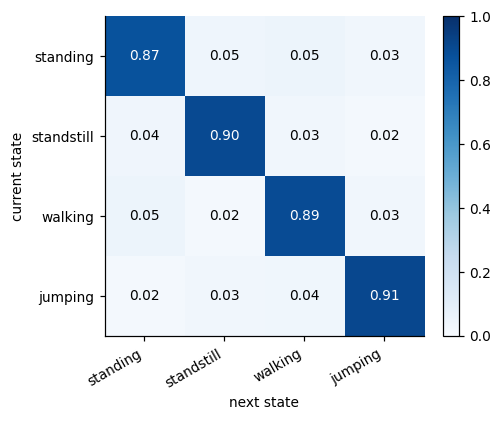

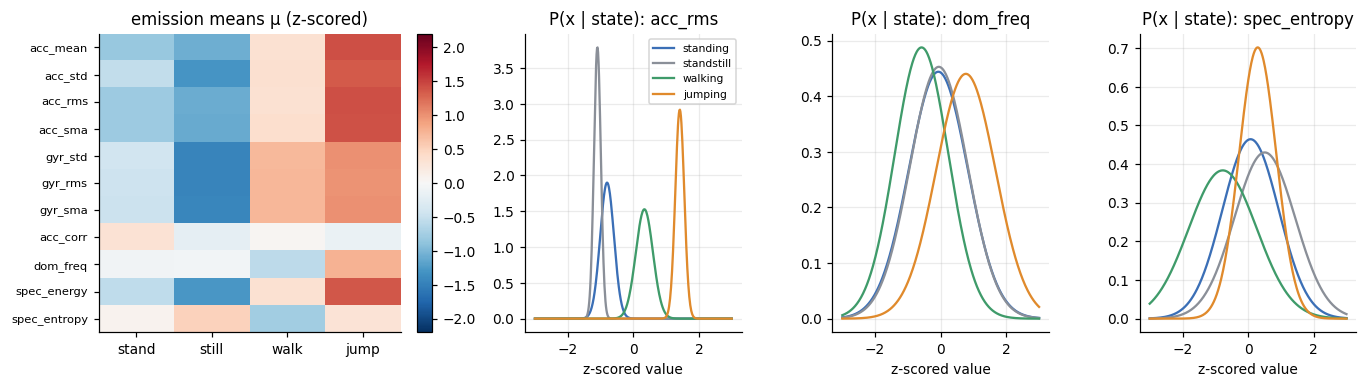

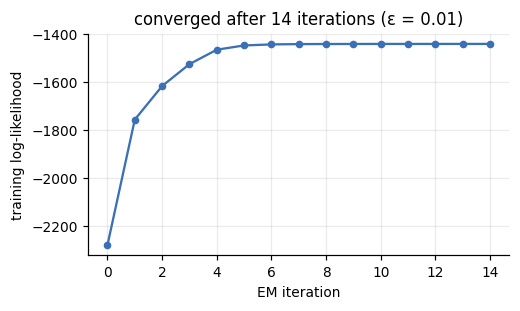

In [15]:
# Figure 4 - transition matrix heatmap (primary model)
A = mP.A
fig, ax = plt.subplots(figsize=(4.6, 3.9))
im = ax.imshow(A, cmap="Blues", vmin=0, vmax=1); ax.grid(False)
ax.set_xticks(range(4)); ax.set_yticks(range(4)); ax.set_xticklabels(ACTS, rotation=30, ha="right"); ax.set_yticklabels(ACTS)
for i in range(4):
    for j in range(4): ax.text(j, i, f"{A[i, j]:.2f}", ha="center", va="center", color="white" if A[i, j] > .5 else "black")
ax.set_xlabel("next state"); ax.set_ylabel("current state"); fig.colorbar(im, fraction=.046)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/fig4_transition_heatmap.png", dpi=170, bbox_inches="tight")
dwell = 1 / (1 - np.diag(A)) * HOP / FS
print("Initial distribution pi:", dict(zip(ACTS, mP.pi.round(3).tolist())))
print("Expected dwell time before leaving a state (s):", dict(zip(ACTS, dwell.round(1).tolist())))

# Figure 5 - emission model: state means and per-state Gaussians for three features
fig = plt.figure(figsize=(12.5, 3.6)); gs = fig.add_gridspec(1, 4, width_ratios=[1.55, 1, 1, 1])
ax = fig.add_subplot(gs[0]); im = ax.imshow(mP.mu.T, cmap="RdBu_r", vmin=-2.2, vmax=2.2, aspect="auto"); ax.grid(False)
ax.set_yticks(range(len(FEATURES))); ax.set_yticklabels(FEATURES, fontsize=7.5); ax.set_xticks(range(4))
ax.set_xticklabels(["stand", "still", "walk", "jump"]); ax.set_title("emission means μ (z-scored)"); fig.colorbar(im, fraction=.05)
xs = np.linspace(-3, 3, 400)
for k, f in enumerate(["acc_rms", "dom_freq", "spec_entropy"]):
    ax = fig.add_subplot(gs[k + 1]); j = FEATURES.index(f)
    for s, a in enumerate(ACTS):
        mu, sd = mP.mu[s, j], np.sqrt(mP.var[s, j]); ax.plot(xs, np.exp(-.5 * ((xs - mu) / sd) ** 2) / (sd * np.sqrt(2 * np.pi)), color=COLORS[a], label=a)
    ax.set_title(f"P(x | state): {f}"); ax.set_xlabel("z-scored value")
    if k == 0: ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/fig5_emissions.png", dpi=170, bbox_inches="tight")

# Figure 6 - Baum-Welch convergence
fig, ax = plt.subplots(figsize=(4.8, 2.9)); ax.plot(range(len(histP)), histP, "o-", color="#3b6fb6", ms=4)
ax.set_xlabel("EM iteration"); ax.set_ylabel("training log-likelihood"); ax.set_title(f"converged after {len(histP) - 1} iterations (ε = {TOL})")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/fig6_baum_welch_convergence.png", dpi=170, bbox_inches="tight")

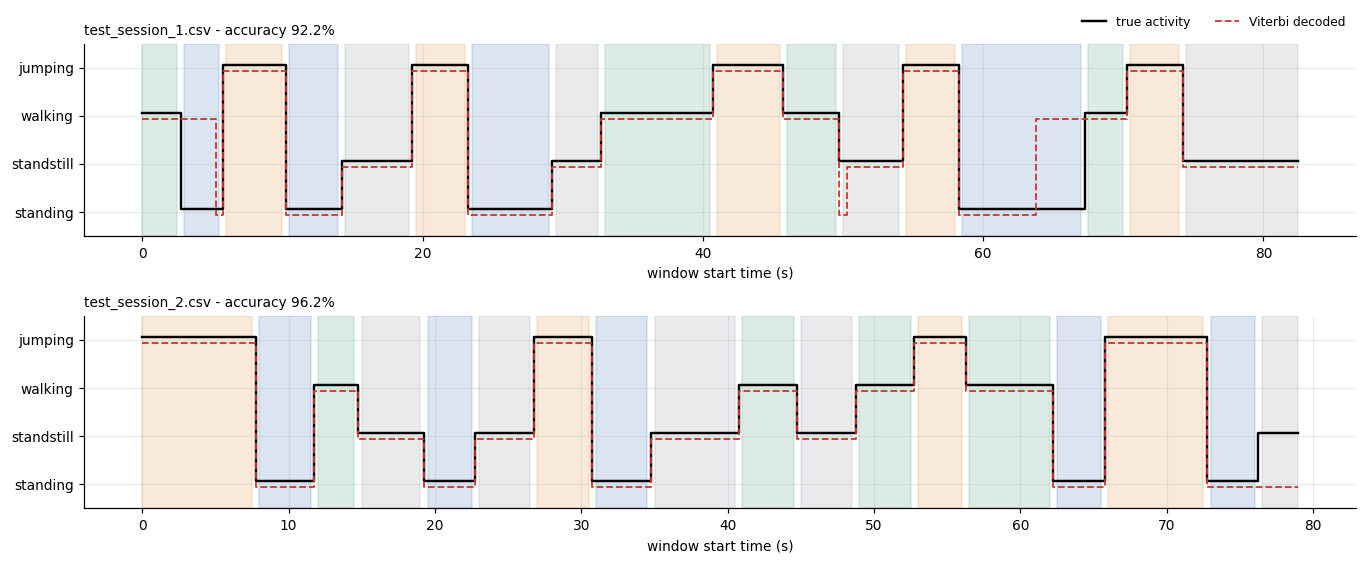

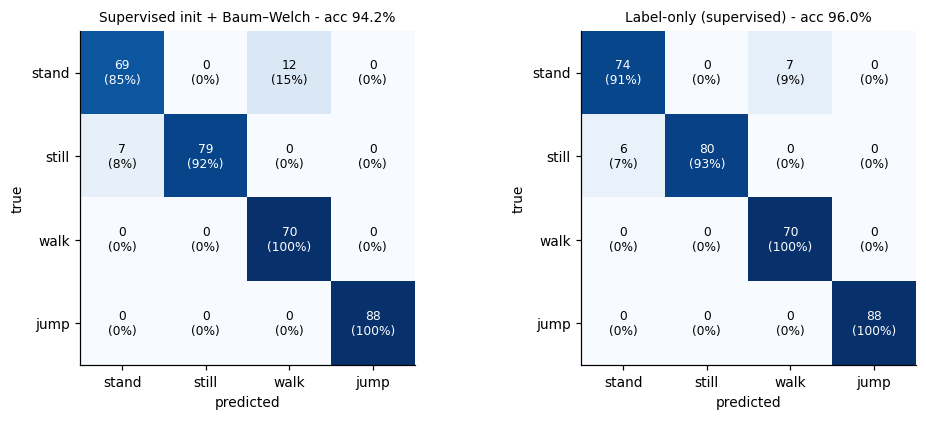

In [16]:
# Figure 7 - decoded sequences vs ground truth for both unseen test files (primary model)
fig, axes = plt.subplots(2, 1, figsize=(12.5, 5.2))
for i, ax in enumerate(axes):
    z, p = test_xy[i][1], results[PRIMARY]["preds"][i]; t = np.arange(len(z)) * HOP / FS
    for k, a in enumerate(ACTS): ax.fill_between(t, 0, 1, where=(z == k), color=COLORS[a], alpha=.18, step="mid", transform=ax.get_xaxis_transform())
    ax.step(t, z + 0.06, where="mid", color="k", lw=1.6, label="true activity")
    ax.step(t, p - 0.06, where="mid", color="#d1342f", lw=1.2, ls="--", label="Viterbi decoded")
    ax.set_yticks(range(4)); ax.set_yticklabels(ACTS); ax.set_ylim(-.5, 3.5); ax.set_xlabel("window start time (s)")
    ax.set_title(f"test_session_{i + 1}.csv - accuracy {(z == p).mean():.1%}", loc="left", fontsize=9)
    if i == 0: ax.legend(loc="lower right", bbox_to_anchor=(1, 1.02), ncol=2, fontsize=8, frameon=False)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/fig7_decoded_sequences.png", dpi=170, bbox_inches="tight")

# Figure 8 - confusion matrices: primary vs label-only
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.9))
for ax, kind, title in zip(axes, ["supervised+BW", "supervised"], ["Supervised init + Baum–Welch", "Label-only (supervised)"]):
    C = results[kind]["C"]; Cn = C / C.sum(1, keepdims=True)
    ax.imshow(Cn, cmap="Blues", vmin=0, vmax=1); ax.grid(False)
    for i in range(4):
        for j in range(4): ax.text(j, i, f"{C[i, j]}\n({Cn[i, j]:.0%})", ha="center", va="center", fontsize=8, color="white" if Cn[i, j] > .5 else "black")
    ax.set_xticks(range(4)); ax.set_yticks(range(4)); ax.set_xticklabels(["stand", "still", "walk", "jump"]); ax.set_yticklabels(["stand", "still", "walk", "jump"])
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"{title} - acc {results[kind]['acc']:.1%}", fontsize=9)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/fig8_confusion_matrices.png", dpi=170, bbox_inches="tight")

## 10. Error analysis

Which *recordings* produce the mistakes, and how do they differ from the typical recording of their class?

In [17]:
E = []
for i in range(2):
    tf = test_feat[i]; order = list(dict.fromkeys(tf.recording))
    tf = pd.concat([tf[tf.recording == r].sort_values("win_start_s") for r in order], ignore_index=True)
    tf["true"] = test_xy[i][1]
    for kind in ["supervised+BW", "supervised"]: tf[kind] = results[kind]["preds"][i]
    tf["file"] = i + 1; E.append(tf)
E = pd.concat(E, ignore_index=True)
class_acc_rms = feat.groupby("activity").acc_rms.mean()
g = E.groupby("recording").apply(lambda d: pd.Series(dict(
        file=int(d.file.iloc[0]), true=ACTS[int(d.true.iloc[0])], windows=len(d),
        err_primary=int((d.true != d["supervised+BW"]).sum()), err_label_only=int((d.true != d["supervised"]).sum()),
        pred_primary=", ".join(sorted({ACTS[int(p)] for p, t in zip(d["supervised+BW"], d.true) if p != t})),
        acc_rms=d.acc_rms.mean(), class_mean_acc_rms=class_acc_rms[ACTS[int(d.true.iloc[0])]],
        gyr_rms=d.gyr_rms.mean(), tilt_deg=d.tilt_deg.mean())))
err_tab = g[(g.err_primary > 0) | (g.err_label_only > 0)].sort_values("err_primary", ascending=False)
print(err_tab.round(3).to_string())
print(f"\n{int(err_tab.err_primary.sum())} of {len(E)} windows wrong (primary) - all in {int((err_tab.err_primary > 0).sum())} of {E.recording.nunique()} test recordings")

               file        true  windows  err_primary  err_label_only pred_primary  acc_rms  class_mean_acc_rms  gyr_rms  tilt_deg
recording                                                                                                                         
standing_05       1    standing       10            7               5      walking    0.450               0.204    0.200    10.652
standstill_36     2  standstill        6            6               6     standing    0.174               0.073    0.007     0.849
standing_20       1    standing        6            5               2      walking    0.502               0.204    0.186    11.984
standstill_09     1  standstill        9            1               0     standing    0.083               0.073    0.002     5.520

19 of 325 windows wrong (primary) - all in 4 of 40 test recordings


## 11. Sensitivity to sampling rate and sensor noise

The phone gave a nearly perfect 100 Hz stream, so the effect of sampling rate and noise is tested *experimentally*:

* **Sampling rate** – every recording is decimated (anti-aliased) to 50 Hz and 25 Hz, the window is kept at 1 s (so 50 / 25 samples), and the complete pipeline (features → scaler → HMM) is re-trained and re-evaluated on the same split.
* **Sensor noise** – white Gaussian noise of increasing σ is added to the accelerometer (m/s²) and gyroscope (rad/s) of the *test* recordings only; the models trained on clean data are re-used unchanged.

In [18]:
from scipy.signal import decimate

def run_at_rate(q):
    global FS, WIN, HOP
    old = (FS, WIN, HOP); FS, WIN, HOP = 100 // q, 100 // q, 50 // q
    try:
        fr = []
        for rec, d in processed.items():
            x = d[SIGNAL_COLS].values
            xd = decimate(x, q, axis=0, zero_phase=True) if q > 1 else x
            dd = pd.DataFrame(xd, columns=SIGNAL_COLS); dd["activity"], dd["recording"] = d.activity.iloc[0], rec
            fr.append(featurise(dd))
        fq = pd.concat(fr, ignore_index=True)
        sc = Scaler(FEATURES).fit(fq[fq.recording.isin(tr_ids_all)])
        xy = [session_xy(fq, s, sc) for s in tr_sessions]; X_, z_ = [a for a, _ in xy], [b for _, b in xy]
        out = {}
        for kind in ["supervised", "supervised+BW"]:
            m, h, smap = train_variant(kind, X_, z_, seed=SEED); ys, ps = [], []
            for s in test_sessions:
                Xt, zt = session_xy(fq, s, sc); ys.append(zt); ps.append(decode(kind, m, smap, Xt))
            out[kind] = float((np.concatenate(ys) == np.concatenate(ps)).mean())
        return out
    finally:
        FS, WIN, HOP = old

rate_rows = []
for q in (1, 2, 4):
    r = run_at_rate(q); rate_rows.append(dict(rate_hz=100 // q, **r))
    print(f"{100 // q:4d} Hz   label-only {r['supervised']:.3f}   supervised+BW {r['supervised+BW']:.3f}")

noise_rows, test_ids = [], [r for s in test_sessions for r in s]
for sigma in (0.0, 0.05, 0.1, 0.2, 0.5):
    rn = np.random.default_rng(7); fr = []
    for rec in test_ids:
        d = processed[rec].copy()
        d[SIGNAL_COLS[:6]] += rn.normal(0, sigma, size=(len(d), 6))
        fr.append(featurise(d))
    fn = pd.concat(fr, ignore_index=True); row = dict(sigma=sigma)
    for kind in ["supervised", "supervised+BW"]:
        m, _, smap = models[kind]; ys, ps = [], []
        for s in test_sessions:
            Xt, zt = session_xy(fn, s, scaler); ys.append(zt); ps.append(decode(kind, m, smap, Xt))
        row[kind] = float((np.concatenate(ys) == np.concatenate(ps)).mean())
        if sigma == 0.05 and kind == "supervised":
            print("confusion at sigma = 0.05 (label-only; rows true, cols predicted):\n", confusion(np.concatenate(ys), np.concatenate(ps)))
    noise_rows.append(row); print(f"noise sigma {sigma:4.2f}   label-only {row['supervised']:.3f}   supervised+BW {row['supervised+BW']:.3f}")

 100 Hz   label-only 0.960   supervised+BW 0.942
  50 Hz   label-only 0.960   supervised+BW 0.948
  25 Hz   label-only 0.962   supervised+BW 0.945
noise sigma 0.00   label-only 0.960   supervised+BW 0.942
confusion at sigma = 0.05 (label-only; rows true, cols predicted):
 [[74  0  7  0]
 [86  0  0  0]
 [ 0  0 70  0]
 [ 0  0  0 88]]
noise sigma 0.05   label-only 0.714   supervised+BW 0.692
noise sigma 0.10   label-only 0.711   supervised+BW 0.674
noise sigma 0.20   label-only 0.680   supervised+BW 0.612
noise sigma 0.50   label-only 0.585   supervised+BW 0.545


In [19]:
out = dict(
    config=dict(fs=FS, win=WIN, hop=HOP, trim_s=TRIM_S, seed=SEED, tol=TOL, var_floor=VAR_FLOOR),
    inventory=dict(device=str(inv.device.iloc[0]), platform=str(inv.platform.iloc[0]), app=str(inv.app_version.iloc[0]),
                   requested_ms=str(inv.requested_ms.iloc[0]), measured_hz=float(inv.acc_hz.mean()), n_files=int(len(inv)),
                   hz_min=float(inv.acc_hz.min()), hz_max=float(inv.acc_hz.max()),
                   raw_dur_min=float(inv.duration_s.min()), raw_dur_max=float(inv.duration_s.max()),
                   n_under5=int((inv.duration_s < 5).sum()), median_gap_ms=float(np.median(gaps)),
                   p99_gap_ms=float(np.percentile(gaps, 99)), max_gap_ms=float(gaps.max()), pct_gap_gt15=float(np.mean(gaps > 15) * 100),
                   total_raw_s={a: float(summary.total_s[a]) for a in ACTS}),
    clean_seconds={a: float(by_act[a]) for a in ACTS},
    windows={a: int((feat.activity == a).sum()) for a in ACTS},
    n_train_windows=int(sum(len(x) for x in tr_X)), n_test_windows=[int(len(x)) for x, _ in test_xy],
    test_files=test_sessions,
    cv=cv_df.to_dict(orient="records"),
    bw=dict(iterations=len(histP) - 1, ll_start=float(histP[0]), ll_end=float(histP[-1]), hist=[float(h) for h in histP]),
    A=mP.A.tolist(), pi=mP.pi.tolist(), dwell_s=dwell.tolist(),
    test={k: dict(acc=v["acc"], acc_per_file=v["acc_per_file"], C=v["C"].tolist(), table=metrics_table(v["C"]).to_dict(orient="records"))
          for k, v in results.items()},
    errors=err_tab.reset_index().to_dict(orient="records"),
    rate_exp=rate_rows, noise_exp=noise_rows,
)
json.dump(out, open("../data/results.json", "w"), indent=1, default=float)
print("saved ../data/results.json")

saved ../data/results.json


## 12. Analysis and reflection

*(All numbers below are produced by the cells above; the notebook is seeded, so re-running reproduces them.)*

**Headline result.** On the two unseen test files (325 windows) the primary model (supervised initialisation + Baum–Welch) reaches **94.2 %** accuracy; the label-only fit reaches **96.0 %**. Jumping is decoded perfectly, walking has 100 % sensitivity, and all 19 errors involve the two low-motion states: standing windows decoded as walking (12) and standstill windows decoded as standing (7).

**Easiest vs. hardest activities.**
* *Jumping* (sensitivity and specificity both 100 %) and *walking* (sensitivity 100 %) are easy: they dominate acceleration energy, gyroscope energy and dominant frequency (≈4 Hz vs ≈2 Hz).
* *Standing* is the hardest (sensitivity 85.2 %) and *standstill* the next (91.9 %). Their feature distributions overlap because both are low-energy and their `dom_freq` / `spec_entropy` are essentially noise.
* Errors are concentrated in **4 of 40 test recordings**: `standing_05` and `standing_20` (restless standing: mean `acc_rms` 0.45 and 0.50 vs. a class mean of 0.20, 12 windows decoded as walking), `standstill_36` (all 6 windows decoded as standing: the phone was flat – tilt 0.85° and gyroscope ≈ 0 – but the accelerometer shows extra vibration, `acc_rms` 0.17 vs 0.07), and one window of `standstill_09`. In other words the model is wrong when a *recording* is atypical for its class, not randomly.

**Baum–Welch vs. label-only.** Baum–Welch converged cleanly (14 iterations, log-likelihood −2280.3 → −1441.1, never decreasing, ε = 0.01), and starting from *random* means it reaches the *same* log-likelihood (−1441.1) and the same test accuracy, so the optimiser is not the issue. Yet EM lowers accuracy (5-fold CV on the training recordings: 97.1 ± 1.0 % label-only vs. 93.5 ± 1.5 % after EM). EM maximises likelihood, not classification accuracy: it shrinks the *standing* variances (e.g. `acc_rms` variance 0.11 → 0.04), which raises the likelihood of typical standing windows but pushes moderately restless ones towards the walking Gaussian. Labelled data should therefore not be thrown away – use EM to refine, but select the variant by validation accuracy.

**Do the transitions help?** Not here. Ignoring A entirely (per-window decision) scores 97.4 ± 0.8 % in CV, within one standard deviation of the HMM (97.1 ± 1.0 %). Windows are already well separated by their features, and the learned A carries little extra information (below).

**Transition probabilities vs. realistic behaviour.** The learned matrix has a strong diagonal (0.87–0.91) and near-uniform off-diagonal entries (0.02–0.05), i.e. an expected stay of 3.8–5.4 s per state. That is **not** a model of natural behaviour: each recording lasts ≈ 4.9 s (≈ 9 windows), so the diagonal is simply ≈ 1 − 1/9, and because recordings were stitched in random order every switch is about equally likely. A realistic matrix (standing → walking more probable than standing → jumping, long dwell in standing/still, short bursts of jumping) would require *continuous* recordings that contain natural transitions; with such data Viterbi smoothing would be expected to matter much more than it does here.

**Sampling rate and sensor noise.**
* The phone delivered 99.84 Hz on average (98.2–100.1 Hz per file); only 0.04 % of sample gaps exceed 15 ms (largest 100 ms), which linear interpolation onto a 100 Hz grid handles. Decimating all data to **50 Hz or 25 Hz** and re-training the full pipeline left accuracy unchanged (label-only 96.0–96.2 %, EM 94.2–94.8 %), so for these body-motion activities ≥ 25 Hz is sufficient and differences between members' phones should disappear after harmonisation.
* **Noise matters far more than rate.** Adding white noise with σ = 0.05 (m/s² and rad/s) to the test signals drops accuracy from 96.0 % to 71.4 %: all 86 standstill windows are decoded as standing. A phone lying flat is characterised by an almost noise-free signal (gyroscope RMS ≈ 0.002 rad/s) and the log-scaled intensity features are extremely sensitive to the noise floor. A noisier phone or a different mounting would need re-training, noise-augmented training, or features that do not rely on the absolute noise floor.

**Limitations (what these results do and do not show).** All 200 recordings come from one phone (Samsung SM-G973F) and one person, so the test files are *new recordings*, not new people or devices – accuracy for other users, phone positions or phones is untested and likely lower. Raw recordings last 4.05–9.24 s (17 are shorter than 5 s, the target range), and the clean signal per activity (≈ 4 min) is well above the 90 s minimum.

**Improvements.**
1. Record several people and phone placements; evaluate leave-one-person-out.
2. Use richer emissions (full-covariance Gaussians or a 2-component mixture for *standing*, to cover calm vs. restless standing) and regularise EM with priors on the variances.
3. Record continuous sequences with real transitions (and add states such as *sitting* or *transition*) so A becomes meaningful.
4. Add orientation information: the gravity-tilt feature from `TotalAcceleration` gave only a small CV gain (97.1 → 97.7 %, within one standard deviation) but separates a flat phone from a held one.
5. Train with noise augmentation and consider barometer / magnetometer channels.